In [1]:
# Celda 1: instalación de dependencias e imports generales
# Instala/importa librerías para manejo de datos, TensorFlow/Keras,
# métricas de sklearn, split estratificado multi-label y fija seeds
# para reproducibilidad.

import os
import glob
import random
import json
from collections import Counter

os.environ["SETUPTOOLS_USE_DISTUTILS"] = "stdlib"
!pip install scikit-learn matplotlib -q

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.metrics import classification_report, f1_score, precision_score, recall_score
import matplotlib.pyplot as plt

# no viene con sklearn, la necesitamos para el split estratificado multi-label
!pip install iterative-stratification -q
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

In [3]:
# Celda 2: descarga del dataset desde S3
# Crea carpetas locales y sincroniza imágenes, labels, classes.txt
# y data.yaml desde el bucket de S3 hacia el entorno local.

LOCAL_DATA_DIR = "data_deteccion"
os.makedirs(f"{LOCAL_DATA_DIR}/images", exist_ok=True)
os.makedirs(f"{LOCAL_DATA_DIR}/labels", exist_ok=True)

BUCKET = "s3://humanoid-damage-cnn-834257582282-us-east-1-an/processed/damage_classification"

import subprocess
subprocess.run(["aws", "s3", "sync", f"{BUCKET}/images/", f"{LOCAL_DATA_DIR}/images/", "--quiet"], check=True)
subprocess.run(["aws", "s3", "sync", f"{BUCKET}/labels/", f"{LOCAL_DATA_DIR}/labels/", "--quiet"], check=True)
subprocess.run(["aws", "s3", "cp", f"{BUCKET}/classes.txt", f"{LOCAL_DATA_DIR}/classes.txt", "--quiet"], check=True)
subprocess.run(["aws", "s3", "cp", f"{BUCKET}/data.yaml", f"{LOCAL_DATA_DIR}/data.yaml", "--quiet"], check=True)

n_images = len(os.listdir(f"{LOCAL_DATA_DIR}/images"))
n_labels = len(os.listdir(f"{LOCAL_DATA_DIR}/labels"))
print(f"Imagenes: {n_images} | Labels: {n_labels}")

Imagenes: 53755 | Labels: 53722


In [4]:
# Celda 3: conteo de imágenes por clase (dataset original)
# Lee classes.txt y todos los archivos de labels.

import glob
from collections import Counter

with open(f"{LOCAL_DATA_DIR}/classes.txt") as f:
    all_classes = [line.strip() for line in f if line.strip()]

orig_id_to_name = {i: name for i, name in enumerate(all_classes)}

conteo_todas = Counter()
for label_path in glob.glob(f"{LOCAL_DATA_DIR}/labels/*.txt"):
    with open(label_path) as f:
        clases_en_imagen = {int(l.split()[0]) for l in f if l.strip()}
    for class_id in clases_en_imagen:
        conteo_todas[orig_id_to_name[class_id]] += 1

print(f"Total de clases en el dataset original: {len(all_classes)}\n")
for name in all_classes:
    print(f"{conteo_todas.get(name, 0):>6}  {name}")


Total de clases en el dataset original: 64

  4456  Concrete spalling
  7649  Corrosion
   505  Crack
   187  Debris
   208  Detachment crack
  2499  Diagonal crack
   352  Flexural/rocking crack
    14  Large displacement
    67  Leaching
   272  Non structural damage
    25  Out-of-plane mechanism
   108  Partial/full collapse
    33  Rebar deformation/buckling
   918  Shear crack
  1261  -1-Earthquake-Induced Cracks And Collapses
   588  -2-Blistering
  2059  -3-Alveolization
   916  -4-Vegetation-Advanced Stage
   553  -5-Detachment
  1016  -6-Pitting
  2291  -7- Swelling
  1160  -8-Flaking
  2810  -9-Exfoliation
  1022  10-Vandalism
   853  11-Crumbling
  1003  12-Corrosion-Local Widespread
  2296  13-Delamination-Localized Spread
   594  14-Encrustation-Localized Spread
   611  0
  1184  1
  1667  crack
   128  damp
     4  dampness
  1003  mold
   158  peeling_paint
   111  stain
   716  stairstep_crack
   135  water_seepage
   100  Efflorescence
   214  -1.Crumbling
   461  -2.

IDs encontrados para '0' y '1': {28, 29}
Total de imágenes encontradas con clase '0' o '1': 1518


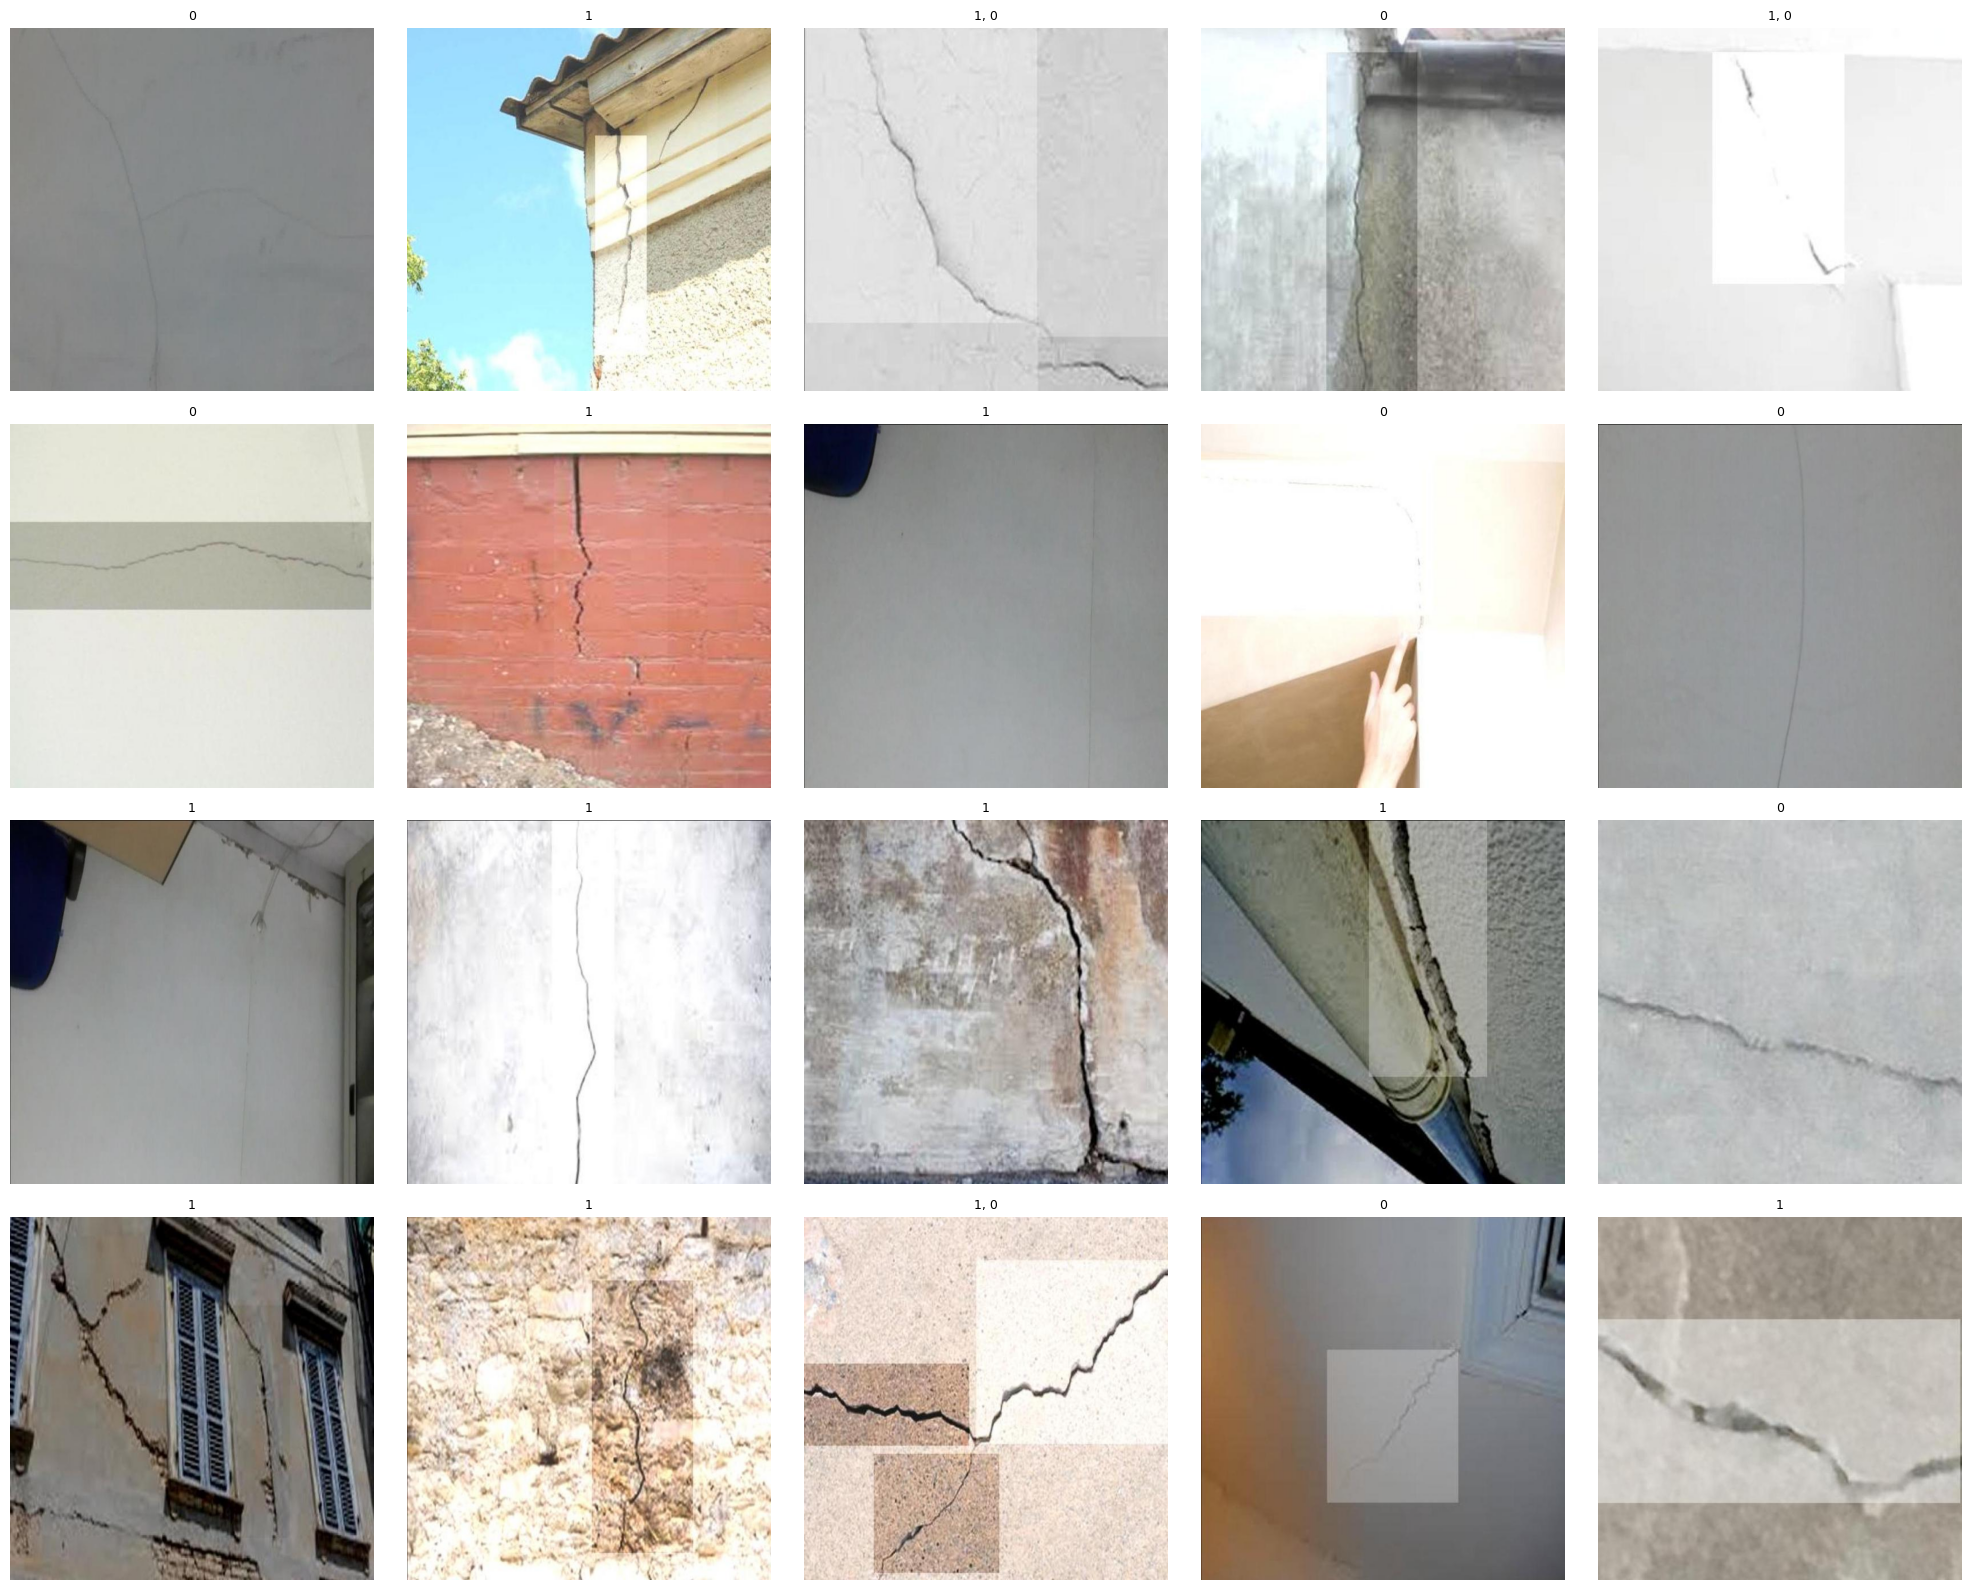

In [5]:
# Celda 4: mostrar 20 imágenes de las clases "0" y "1"
# Busca los IDs correspondientes a los nombres "0" y "1" en classes.txt,
# recorre los labels para encontrar imágenes que contengan esas clases,
# toma una muestra aleatoria de 20 y las grafica con su clase como título.
# Depende de: LOCAL_DATA_DIR, all_classes, orig_id_to_name (celdas anteriores)
import matplotlib.pyplot as plt
from PIL import Image
import random

# IDs correspondientes a los nombres "0" y "1" en classes.txt
ids_objetivo = {cid for cid, name in orig_id_to_name.items() if name in ("0", "1")}
print("IDs encontrados para '0' y '1':", ids_objetivo)

# Buscar imágenes que contengan esas clases
imagenes_encontradas = []
for label_path in glob.glob(f"{LOCAL_DATA_DIR}/labels/*.txt"):
    with open(label_path) as f:
        clases_en_imagen = {int(l.split()[0]) for l in f if l.strip()}
    if clases_en_imagen & ids_objetivo:
        nombre_base = os.path.splitext(os.path.basename(label_path))[0]
        # buscar la imagen correspondiente (puede ser .jpg, .png, etc.)
        posibles = glob.glob(f"{LOCAL_DATA_DIR}/images/{nombre_base}.*")
        if posibles:
            clases_nombres = {orig_id_to_name[cid] for cid in clases_en_imagen & ids_objetivo}
            imagenes_encontradas.append((posibles[0], clases_nombres))

print(f"Total de imágenes encontradas con clase '0' o '1': {len(imagenes_encontradas)}")

# Elegir 20 al azar
random.seed(42)
muestra = random.sample(imagenes_encontradas, min(20, len(imagenes_encontradas)))

# Graficar
n = len(muestra)
cols = 5
rows = (n + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(4*cols, 4*rows))
axes = axes.flatten()

for ax, (img_path, clases_nombres) in zip(axes, muestra):
    img = Image.open(img_path)
    ax.imshow(img)
    ax.set_title(", ".join(clases_nombres), fontsize=9)
    ax.axis("off")

for ax in axes[len(muestra):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Celda 5: explorar TODOS los grupos antes de fusionar (versión optimizada)
# Recorre labels/*.txt UNA sola vez y arma un índice {clase: [imagenes]}.
# Con ese índice muestra 5 imágenes de cada subclase por separado, y 5
# imágenes de la superclase resultante (unión), para cada grupo propuesto.
# Depende de: LOCAL_DATA_DIR, orig_id_to_name (celdas anteriores)
import matplotlib.pyplot as plt
from PIL import Image
import random
from collections import defaultdict

# ---- 1. Indexar UNA sola vez: nombre_clase -> lista de rutas de imagen ----
indice_clase_a_imagenes = defaultdict(list)

for label_path in glob.glob(f"{LOCAL_DATA_DIR}/labels/*.txt"):
    with open(label_path) as f:
        clases_en_imagen = {int(l.split()[0]) for l in f if l.strip()}
    if not clases_en_imagen:
        continue
    nombre_base = os.path.splitext(os.path.basename(label_path))[0]
    posibles = glob.glob(f"{LOCAL_DATA_DIR}/images/{nombre_base}.*")
    if not posibles:
        continue
    ruta_imagen = posibles[0]
    for class_id in clases_en_imagen:
        nombre_clase = orig_id_to_name[class_id]
        indice_clase_a_imagenes[nombre_clase].append(ruta_imagen)

print(f"Índice armado. Clases indexadas: {len(indice_clase_a_imagenes)}")

# ---- 2. Funciones de muestreo, usando solo el índice (sin volver a leer disco) ----
def muestra_subclase(nombre_clase, n=5, seed=42):
    rutas = indice_clase_a_imagenes.get(nombre_clase, [])
    random.seed(seed)
    return random.sample(rutas, min(n, len(rutas)))

def muestra_superclase(lista_subclases, n=5, seed=42):
    rutas = set()
    for sub in lista_subclases:
        rutas.update(indice_clase_a_imagenes.get(sub, []))
    rutas = list(rutas)
    random.seed(seed)
    return random.sample(rutas, min(n, len(rutas)))

def graficar(titulo, rutas):
    if not rutas:
        print(f"{titulo}: sin imágenes encontradas")
        return
    fig, axes = plt.subplots(1, len(rutas), figsize=(4*len(rutas), 4))
    if len(rutas) == 1:
        axes = [axes]
    for ax, ruta in zip(axes, rutas):
        img = Image.open(ruta)
        ax.imshow(img)
        ax.axis("off")
    fig.suptitle(titulo, fontsize=14)
    plt.tight_layout()
    plt.show()

def explorar_grupo(nombre_superclase, subclases, n=5):
    print(f"\n{'#'*70}\nGRUPO: {nombre_superclase}\n{'#'*70}")
    for sub in subclases:
        rutas = muestra_subclase(sub, n=n)
        graficar(f"{nombre_superclase} <- {sub} ({len(indice_clase_a_imagenes.get(sub, []))} imgs totales)", rutas)

    rutas_super = muestra_superclase(subclases, n=n)
    total_super = len(set().union(*[indice_clase_a_imagenes.get(s, []) for s in subclases]))
    graficar(f"SUPERCLASE FINAL: {nombre_superclase} ({total_super} imgs totales)", rutas_super)


# ---- Todos los grupos propuestos en la Parte 2 ----
GRUPOS = {
    "Structural crack": ["Diagonal crack", "Flexural/rocking crack", "Shear crack",
                          "Detachment crack", "stairstep_crack"],
    "Severe structural failure": ["Partial/full collapse", "Large displacement",
                                   "Out-of-plane mechanism",
                                   "-1-Earthquake-Induced Cracks And Collapses"],
    "Surface flaking/exfoliation": ["-2-Blistering", "-8-Flaking", "peeling_paint",
                                     "-9-Exfoliation", "15.Friability", "-3-Alveolization"],
    "Salt weathering": ["-5-Salt Crystallization", "16.Subflorescence",
                         "17.Sugaring", "18.Surface Crust"],
    "Material loss/erosion": ["12.Disintegration", "14. Erosion",
                               "20. Loss Of Material-Lack"],
    "Moisture/water damage": ["water_seepage", "-7. Water Damage-Rising-Damp",
                               "Soil moisture", "Stagnant water", "Wet surface"],
    "Biological growth": ["10.Biological Colonization-Microbial",
                           "21.Patina Biologica", "mold"],
    "Surface deposits/incrustation": ["11. Surface Deposits",
                                       "14-Encrustation-Localized Spread",
                                       "8-Chromatic Alteration"],
}

for nombre_superclase, subclases in GRUPOS.items():
    explorar_grupo(nombre_superclase, subclases, n=5)

In [ ]:
# Resumen de distribución de clases finales (post-fusión) para diagnóstico
# de desbalance. Es multi-label: una imagen puede aportar a varias clases
# a la vez, por eso la suma de "imagenes" es mayor al total del dataset.
# Calcula, por clase: cantidad de imagenes, % del dataset, cuántas imágenes
# tienen ESA clase como única etiqueta ("solo esta clase"), y un peso
# sugerido (inverso a la frecuencia) para usar en class_weight o en una
# loss ponderada. También reporta cuántas etiquetas tiene cada imagen en
# promedio, qué tan multi-label es realmente el dataset, y marca las
# clases con muy pocos ejemplos "puros" (candidatas a necesitar
# augmentation agresivo, oversampling, o revisar si conviene fusionarlas).
# Termina con un gráfico de barras horizontal para ver el desbalance
# de un vistazo. Depende de: df, FINAL_CLASSES (definidos previamente).
resumen = pd.DataFrame({
    "imagenes": df[FINAL_CLASSES].sum(),
    "% del dataset": (df[FINAL_CLASSES].mean() * 100).round(1),
    # imagenes donde ese daño es el unico presente
    "solo esta clase": [
        int(((df[cls] == 1) & (df[FINAL_CLASSES].sum(axis=1) == 1)).sum())
        for cls in FINAL_CLASSES
    ],
}).sort_values("imagenes", ascending=False)

# peso sugerido para la loss (inverso a la frecuencia, normalizado
# para que el promedio de los pesos sea 1). Util para class_weight
# o para ponderar la loss por clase y compensar el desbalance
n_total = len(df)
resumen["peso_sugerido"] = (n_total / (len(FINAL_CLASSES) * resumen["imagenes"])).round(2)

print(f"Total de imagenes en el dataset: {n_total}\n")
print(resumen)

print(f"\nClase mas frecuente: {resumen.index[0]} ({resumen['imagenes'].iloc[0]})")
print(f"Clase menos frecuente: {resumen.index[-1]} ({resumen['imagenes'].iloc[-1]})")
print(f"Desbalance (mayor/menor): {resumen['imagenes'].iloc[0] / max(resumen['imagenes'].iloc[-1], 1):.1f}x")

# cuantas etiquetas tiene cada imagen en promedio (multi-label)
n_labels_por_imagen = df[FINAL_CLASSES].sum(axis=1)
print(f"\nEtiquetas por imagen -> promedio: {n_labels_por_imagen.mean():.2f}, "
      f"min: {n_labels_por_imagen.min()}, max: {n_labels_por_imagen.max()}")
print(f"Imagenes con mas de 1 clase (multi-label real): "
      f"{(n_labels_por_imagen > 1).sum()} ({(n_labels_por_imagen > 1).mean()*100:.1f}%)")

# clases criticamente chicas (menos de 50 imagenes con "solo esta clase")
# candidatas fuertes a necesitar augmentation agresivo, oversampling,
# o directamente revisar si conviene fusionarlas con otra clase
umbral_critico = 50
clases_criticas = resumen[resumen["solo esta clase"] < umbral_critico]
if len(clases_criticas) > 0:
    print(f"\nClases con menos de {umbral_critico} imagenes 'puras' (posible sobreajuste/ruido):")
    print(clases_criticas[["imagenes", "solo esta clase"]])

# grafico de barras para visualizar el desbalance de un vistazo
plt.figure(figsize=(10, max(4, len(FINAL_CLASSES) * 0.35)))
plt.barh(resumen.index[::-1], resumen["imagenes"][::-1])
plt.xlabel("cantidad de imagenes")
plt.title("distribucion de imagenes por clase final")
plt.tight_layout()
plt.show()

In [ ]:
X = df["image_path"].values.reshape(-1, 1)
y = df[FINAL_CLASSES].values

msss = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
train_idx, val_idx = next(msss.split(X, y))

train_df = df.iloc[train_idx].reset_index(drop=True)
val_df = df.iloc[val_idx].reset_index(drop=True)

print(f"train: {len(train_df)} | val: {len(val_df)}")
print(train_df[FINAL_CLASSES].sum())
print(val_df[FINAL_CLASSES].sum())

In [ ]:
# oversampling: duplicamos ejemplos de las clases con menos imagenes hasta acercarnos
# a la clase mas grande. como una imagen puede tener mas de un daño, esto de paso
# empuja un poco a las clases que suelen aparecer junto a la minoritaria
target = train_df[FINAL_CLASSES].sum().max()

partes = [train_df]
for cls in FINAL_CLASSES:
    actual = train_df[cls].sum()
    faltante = target - actual
    if faltante <= 0:
        continue
    candidatos = train_df[train_df[cls] == 1]
    extra = candidatos.sample(n=int(faltante), replace=True, random_state=42)
    partes.append(extra)

train_df_balanced = pd.concat(partes, ignore_index=True)
train_df_balanced = train_df_balanced.sample(frac=1, random_state=42).reset_index(drop=True)

print(f"train antes del oversampling: {len(train_df)}, despues: {len(train_df_balanced)}")
print(train_df_balanced[FINAL_CLASSES].sum())

In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    return img, label

# el flip horizontal deberia estar bien para grietas y daños estructurales en general,
# pero si en algun momento notas que la orientacion importa para alguna clase, sacalo
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomBrightness(0.1),
])

def make_dataset(dataframe, training):
    paths = dataframe["image_path"].values
    labels = dataframe[FINAL_CLASSES].values.astype("float32")
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.shuffle(2000, seed=42)
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y),
                    num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_df_balanced, training=True)
val_ds = make_dataset(val_df, training=False)

In [ ]:
base_model = EfficientNetB0(include_top=False, weights="imagenet", input_shape=IMG_SIZE + (3,))
base_model.trainable = False

inputs = layers.Input(shape=IMG_SIZE + (3,))
x = tf.keras.applications.efficientnet.preprocess_input(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.2)(x)

# sigmoid, no softmax: cada daño es independiente, una imagen puede tener varios a la vez
outputs = layers.Dense(len(FINAL_CLASSES), activation="sigmoid")(x)

model = models.Model(inputs, outputs)
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.AUC(name="auc", multi_label=True),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
    ],
)
model.summary()

In [ ]:
# esto imprime precision/recall/f1 de cada tipo de daño al final de cada epoca,
# no solo el promedio general que muestra el fit() por defecto
class MetricasPorDano(tf.keras.callbacks.Callback):
    def __init__(self, val_dataset, class_names, threshold=0.5):
        super().__init__()
        self.val_dataset = val_dataset
        self.class_names = class_names
        self.threshold = threshold

    def on_epoch_end(self, epoch, logs=None):
        y_true = np.concatenate([y.numpy() for _, y in self.val_dataset], axis=0)
        y_probs = self.model.predict(self.val_dataset, verbose=0)
        y_pred = (y_probs > self.threshold).astype(int)

        print(f"\nmetricas por clase (umbral {self.threshold}) - fin de epoca {epoch + 1}")
        for i, cls in enumerate(self.class_names):
            p = precision_score(y_true[:, i], y_pred[:, i], zero_division=0)
            r = recall_score(y_true[:, i], y_pred[:, i], zero_division=0)
            f1 = f1_score(y_true[:, i], y_pred[:, i], zero_division=0)
            print(f"  {cls:28s} precision {p:.2f}  recall {r:.2f}  f1 {f1:.2f}")

metricas_callback = MetricasPorDano(val_ds, FINAL_CLASSES)

In [ ]:
callbacks = [
    EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3),
    ModelCheckpoint("modelo_danos.keras", monitor="val_loss", save_best_only=True),
    metricas_callback,
]

# fase 1: la base va congelada, solo entrena la cabeza nueva
history_head = model.fit(train_ds, validation_data=val_ds, epochs=15, callbacks=callbacks)

In [ ]:
# fase 2: descongelamos el ultimo 20% de EfficientNet y afinamos con LR bajo
base_model.trainable = True
fine_tune_at = int(len(base_model.layers) * 0.8)
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.AUC(name="auc", multi_label=True),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
    ],
)

history_fine = model.fit(train_ds, validation_data=val_ds, epochs=15, callbacks=callbacks)

In [ ]:
val_probs = model.predict(val_ds)
val_true = val_df[FINAL_CLASSES].values

# con clases desbalanceadas el umbral 0.5 casi nunca es el mejor, probamos varios
# por clase y nos quedamos con el que da mejor f1 en validacion
best_thresholds = {}
for i, cls in enumerate(FINAL_CLASSES):
    best_f1, best_t = 0, 0.5
    for t in np.arange(0.1, 0.9, 0.05):
        preds = (val_probs[:, i] > t).astype(int)
        f1 = f1_score(val_true[:, i], preds, zero_division=0)
        if f1 > best_f1:
            best_f1, best_t = f1, t
    best_thresholds[cls] = round(float(best_t), 2)
    print(f"{cls}: umbral {best_t:.2f}, f1 {best_f1:.3f}")

val_preds_tuned = np.array([
    (val_probs[:, i] > best_thresholds[cls]).astype(int)
    for i, cls in enumerate(FINAL_CLASSES)
]).T

print(classification_report(val_true, val_preds_tuned, target_names=FINAL_CLASSES, zero_division=0))

In [ ]:
def predecir_danios(ruta_imagen, umbral_por_clase=best_thresholds):
    img = tf.io.read_file(ruta_imagen)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.expand_dims(img, 0)

    probs = model.predict(img, verbose=0)[0]
    detectados = [
        (FINAL_CLASSES[i], float(probs[i]))
        for i in range(len(FINAL_CLASSES))
        if probs[i] > umbral_por_clase[FINAL_CLASSES[i]]
    ]
    detectados.sort(key=lambda x: x[1], reverse=True)
    return detectados

# predecir_danios("data_deteccion/images/alguna_imagen.jpg")

In [ ]:
model.save("modelo_danos_estructurales.keras")

with open("thresholds.json", "w") as f:
    json.dump(best_thresholds, f, indent=2)

print("modelo y thresholds guardados")